# 09 機器學習與穩健性檢查

## A. 機器學習：如果真的有複雜的個人差異，讓演算法自己找

線性模型只能檢驗我們「想到」的交互作用。梯度提升樹（Gradient Boosting, Friedman, 2001）可以自動找出任何非線性與交互作用。
關鍵設計：同一個演算法跑兩次——
- **加法版**：用 `interaction_cst` 強迫每個變數只能單獨作用（不能和其他變數交互作用）；
- **完整版**：允許任意交互作用（例如「重視家庭的人 × 家庭滿意度」、「有小孩 × 工作滿意度」）。

如果「每個人的權重不同」這件事很重要，完整版的預測力應該明顯高於加法版。這是一個不預設模型形式的檢驗。

In [1]:
import numpy as np, pandas as pd
import statsmodels.formula.api as smf
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance, partial_dependence
from psfd_utils import *
plt = setup_plot()
main = pd.read_csv(DERIVED / "main_2020_2024.csv", low_memory=False)
emp = main[main.employed == 1].dropna(subset=["swb", "jobsat", "famsat", "econsat", "health", "age", "female"]).copy()
FEAT = ["jobsat", "famsat", "econsat", "health", "age", "female", "married", "nkids", "kid_under6", "log_income",
        "edu_years", "hours", "web", "year", "breadwinner"]
NAMES = dict(jobsat="工作滿意", famsat="家庭滿意", econsat="經濟滿意", health="健康", age="年齡", female="女性", married="已婚",
             nkids="子女數", kid_under6="有幼兒", log_income="收入(log)", edu_years="教育年數", hours="工時", web="網路自填",
             year="年份", breadwinner="傳統分工觀")
X = emp[FEAT].astype(float).values; y = emp.swb.values; groups = emp.pid.values
print("N =", len(y))


def gcv(model, X, y, k=5):
    out = []
    for tr, te in GroupKFold(k).split(X, y, groups):      # 同一人不會同時出現在訓練與測試
        m = model.fit(X[tr], y[tr]); p = m.predict(X[te])
        out.append(1 - ((y[te] - p) ** 2).sum() / ((y[te] - y[te].mean()) ** 2).sum())
    return np.mean(out), np.std(out)


add_cst = [[i] for i in range(len(FEAT))]
models = {
    "線性迴歸（只有主效果）": None,
    "梯度提升・加法（不允許交互作用）": HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=15, interaction_cst=add_cst, random_state=0),
    "梯度提升・完整（允許任意交互作用）": HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=15, random_state=0),
}
Xl = emp[FEAT].copy()
Xl = Xl.fillna(Xl.median()).values          # 線性迴歸不能有缺失
rows = []
for nm, mdl in models.items():
    if mdl is None:
        r = gcv(LinearRegression(), Xl, y)
    else:
        r = gcv(mdl, X, y)
    rows.append(dict(模型=nm, CV_R2=r[0], 標準差=r[1]))
mlres = pd.DataFrame(rows).round(4)
mlres

N = 13079


,模型,CV_R2,標準差
0,線性迴歸（只有主效果）,0.4006,0.0117
1,梯度提升・加法（不允許交互作用）,0.4027,0.0094
2,梯度提升・完整（允許任意交互作用）,0.4027,0.0121


### 只允許「態度/人生階段 × 工作、家庭滿意度」的交互作用
更精準的檢驗：只放開我們關心的那幾組交互作用（權重隨人改變），其他維持加法。

In [2]:
idx = {f: i for i, f in enumerate(FEAT)}
mods = ["age", "female", "married", "nkids", "kid_under6", "breadwinner", "log_income"]
cst = [[idx["jobsat"]] + [idx[m] for m in mods], [idx["famsat"]] + [idx[m] for m in mods]] + [[i] for f, i in idx.items() if f not in ("jobsat", "famsat")]
r = gcv(HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=15, interaction_cst=cst, random_state=0), X, y)
print("只允許『權重隨人改變』的交互作用：CV R² = %.4f（±%.4f）" % r)

只允許『權重隨人改變』的交互作用：CV R² = 0.4022（±0.0084）


### 哪些變數最重要？（置換重要性）與部分依賴圖

In [3]:
gb = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=15, random_state=0).fit(X, y)
pi = permutation_importance(gb, X, y, n_repeats=5, random_state=0, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=[NAMES[f] for f in FEAT]).sort_values(ascending=False)
imp.round(4)

家庭滿意       0.1818
健康         0.1219
工作滿意       0.0971
經濟滿意       0.0773
網路自填       0.0252
收入(log)    0.0163
工時         0.0157
年齡         0.0106
子女數        0.0086
教育年數       0.0084
已婚         0.0079
傳統分工觀      0.0075
年份         0.0059
有幼兒        0.0016
女性         0.0013
dtype: float64

PosixPath('figures/fig09_pdp.png')

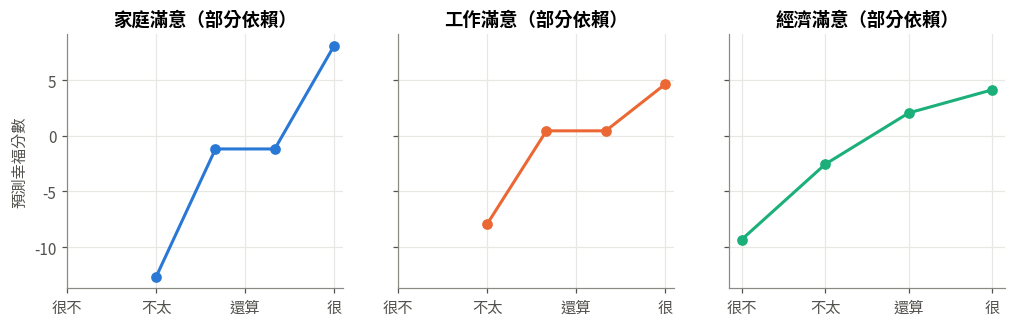

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for ax, f, col in zip(axes, ["famsat", "jobsat", "econsat"], [C_FAMILY, C_WORK, C_ECON]):
    pdp = partial_dependence(gb, X, [idx[f]], grid_resolution=4, kind="average")
    ax.plot(pdp["grid_values"][0], pdp["average"][0], marker="o", color=col)
    ax.set_xticks([1, 2, 3, 4], ["很不", "不太", "還算", "很"]); ax.set_title(NAMES[f] + "（部分依賴）")
axes[0].set_ylabel("預測幸福分數")
savefig(fig, "fig09_pdp")

## B. 穩健性：換一種量法，結論還一樣嗎？

主結論是「家庭的權重 > 工作」。以下逐一更換結果變數、樣本、模型，看家庭與工作的標準化係數是否維持同樣的順序。

In [5]:
def betas(d, dv, extra="", ctrl="econsat_z + health_z + age + I(age**2) + female + web + C(year)"):
    d = d.copy()
    for c in [dv, "jobsat", "famsat", "econsat", "health"]:
        d[c + "_z"] = d.groupby("year")[c].transform(z) if c in d else np.nan
    f = f"{dv}_z ~ jobsat_z + famsat_z + {ctrl} {extra}"
    m0 = smf.ols(f, d).fit()
    m = smf.ols(f, d).fit(cov_type="cluster", cov_kwds={"groups": d.loc[m0.model.data.row_labels, "pid"]})
    return m.params["famsat_z"], m.params["jobsat_z"], int(m.nobs)


rob = []
add = lambda nm, r: rob.append(dict(檢查=nm, 家庭=r[0], 工作=r[1], N=r[2]))
add("主模型：三面向幸福指數", betas(emp, "swb"))
add("只用『快樂』一題", betas(emp, "happy"))
add("只用『生活過得好不好』", betas(emp, "good"))
add("只用情緒 6 題", betas(emp, "affect6"))
add("兩題版（快樂＋生活評價）", betas(emp, "swb2"))
add("社會連結／不寂寞（不同概念，參考）", betas(emp, "social6"))
add("只有面訪", betas(emp[emp.web == 0], "swb"))
add("只有網路自填", betas(emp[emp.web == 1], "swb"))
add("只有原始主樣本", betas(emp[emp.respondent_type == 1], "swb"))
add("只有子女轉主樣本（較年輕）", betas(emp[emp.respondent_type == 3], "swb"))
add("男性", betas(emp[emp.female == 0], "swb", ctrl="econsat_z + health_z + age + I(age**2) + web + C(year)"))
add("女性", betas(emp[emp.female == 1], "swb", ctrl="econsat_z + health_z + age + I(age**2) + web + C(year)"))
add("不控制經濟與健康", betas(emp, "swb", ctrl="age + I(age**2) + female + web + C(year)"))
add("加控制收入、教育、婚姻、子女", betas(emp, "swb", extra="+ log_income + edu_years + married + nkids"))
for y_ in [2020, 2022, 2024]:
    add(f"只有 {y_}", betas(emp[emp.year == y_], "swb", ctrl="econsat_z + health_z + age + I(age**2) + female + web"))
rob = pd.DataFrame(rob)
rob["家庭>工作"] = rob.家庭 > rob.工作
rob.round(3)

,檢查,家庭,工作,N,家庭>工作
0,主模型：三面向幸福指數,0.288,0.199,13079,True
1,只用『快樂』一題,0.272,0.210,13079,True
2,只用『生活過得好不好』,0.259,0.159,13079,True
3,只用情緒 6 題,0.183,0.127,13079,True
4,兩題版（快樂＋生活評價）,0.285,0.197,13079,True
5,社會連結／不寂寞（不同概念，參考）,0.240,0.133,12985,True
6,只有面訪,0.292,0.183,9005,True
7,只有網路自填,0.276,0.226,4074,True
8,只有原始主樣本,0.292,0.196,8987,True
9,只有子女轉主樣本（較年輕）,0.277,0.206,4092,True


### 已婚者：用「婚姻滿意度」取代「家庭生活滿意度」

In [6]:
mar = emp[emp.marsat.notna()].copy()
for c in ["swb", "jobsat", "famsat", "marsat", "econsat", "health"]:
    mar[c + "_z"] = mar.groupby("year")[c].transform(z)
for f in ["swb_z ~ jobsat_z + marsat_z", "swb_z ~ jobsat_z + famsat_z", "swb_z ~ jobsat_z + famsat_z + marsat_z"]:
    m = smf.ols(f + " + econsat_z + health_z + age + female + web + C(year)", mar).fit()
    print(f"{f:45s}", {k: round(v, 3) for k, v in m.params.items() if k in ("jobsat_z", "famsat_z", "marsat_z")}, "R²=%.3f" % m.rsquared)

swb_z ~ jobsat_z + marsat_z                   {'jobsat_z': 0.207, 'marsat_z': 0.247} R²=0.383
swb_z ~ jobsat_z + famsat_z                   {'jobsat_z': 0.181, 'famsat_z': 0.291} R²=0.396
swb_z ~ jobsat_z + famsat_z + marsat_z        {'jobsat_z': 0.176, 'famsat_z': 0.216, 'marsat_z': 0.154} R²=0.412


### 序位模型（ordered logit）：把「快樂」1–7 當成順序類別
依 Ferrer-i-Carbonell & Frijters (2004)，若 OLS 與序位模型結論一致，就能放心用 OLS 的「分數」來說故事。

In [7]:
from statsmodels.miscmodels.ordinal_model import OrderedModel
d = emp.dropna(subset=["happy"]).copy()
for c in ["jobsat", "famsat", "econsat", "health"]:
    d[c + "_z"] = d.groupby("year")[c].transform(z)
om = OrderedModel(d.happy.astype(int), d[["jobsat_z", "famsat_z", "econsat_z", "health_z", "age", "female", "web"]], distr="logit").fit(method="bfgs", disp=False)
ol = smf.ols("happy ~ jobsat_z + famsat_z + econsat_z + health_z + age + female + web", d).fit()
cmp = pd.DataFrame({"ordered logit": om.params[["jobsat_z", "famsat_z", "econsat_z", "health_z"]], "OLS": ol.params[["jobsat_z", "famsat_z", "econsat_z", "health_z"]]})
cmp["比例（家庭=1）"] = cmp["ordered logit"] / cmp.loc["famsat_z", "ordered logit"]
cmp["OLS 比例"] = cmp["OLS"] / cmp.loc["famsat_z", "OLS"]
cmp.round(3)

,ordered logit,OLS,比例（家庭=1）,OLS 比例
jobsat_z,0.490,0.264,0.800,0.768
famsat_z,0.613,0.344,1.000,1.000
econsat_z,0.265,0.153,0.433,0.444
health_z,0.492,0.260,0.803,0.756


### 2020 的延伸工作分數：加入工作特性與職家衝突後，工作的總影響有多大？

In [8]:
e20 = emp[emp.year == 2020].copy()
JC = [f"jobchar_{i:02d}" for i in range(13)]
e20 = e20.dropna(subset=JC + ["wfc"])
for c in ["swb", "jobsat", "famsat", "econsat", "health", "wfc"] + JC:
    e20[c] = z(e20[c])
base = smf.ols("swb ~ jobsat + famsat + econsat + health + age + female + web", e20).fit()
ext = smf.ols("swb ~ jobsat + famsat + econsat + health + wfc + " + " + ".join(JC) + " + age + female + web", e20).fit()
print("N =", int(base.nobs))
print("只有工作滿意度：R² = %.4f；加入工作特性 13 題與職家衝突：R² = %.4f（+%.4f）" % (base.rsquared, ext.rsquared, ext.rsquared - base.rsquared))
print("職家衝突係數：%.3f" % ext.params["wfc"])

N = 4066
只有工作滿意度：R² = 0.3924；加入工作特性 13 題與職家衝突：R² = 0.4466（+0.0542）
職家衝突係數：-0.163


In [9]:
mlres.to_csv(DERIVED / "ml_additive_vs_full.csv", index=False)
rob.to_csv(DERIVED / "robustness.csv", index=False)